In [2]:
%pip install -q kagglehub pandas matplotlib

In [3]:
import os

import kagglehub
import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_colwidth", 200)

In [4]:
try:  # lê a chave do Kaggle dos Secrets do Colab, se existir
    from google.colab import userdata
    os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
    os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")
except Exception:
    pass  # fora do Colab ou sem Secrets: o dataset é público e costuma baixar mesmo assim

caminho = kagglehub.dataset_download("olistbr/brazilian-ecommerce")
df = pd.read_csv(f"{caminho}/olist_order_reviews_dataset.csv")

print(f"{df.shape[0]:,} avaliações, {df.shape[1]} colunas")
df.head()

Using Colab cache for faster access to the 'brazilian-ecommerce' dataset.
99,224 avaliações, 7 colunas


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela Internet seguro e prático Parabéns a todos feliz Páscoa,2018-03-01 00:00:00,2018-03-02 10:26:53


In [5]:
tem_texto = df["review_comment_message"].notna()
print(f"Com comentário: {tem_texto.sum():,} ({tem_texto.mean():.1%})")
print(f"Sem comentário: {(~tem_texto).sum():,}")

Com comentário: 40,977 (41.3%)
Sem comentário: 58,247


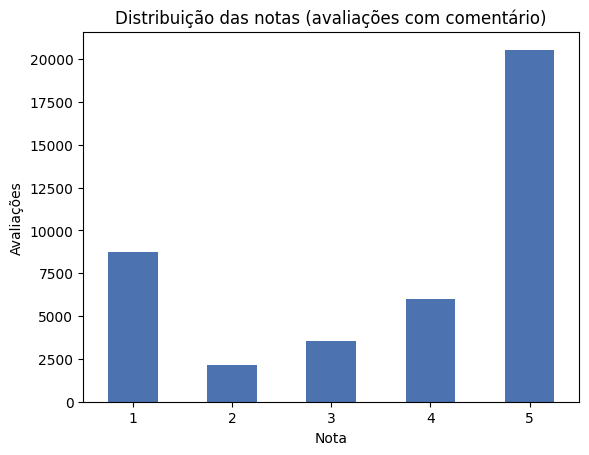

review_score
1    0.213
2    0.052
3    0.087
4    0.146
5    0.502
Name: count, dtype: float64


In [6]:
com_texto = df[tem_texto].copy()
distribuicao = com_texto["review_score"].value_counts().sort_index()

ax = distribuicao.plot(kind="bar", color="#4C72B0")
ax.set_xlabel("Nota")
ax.set_ylabel("Avaliações")
ax.set_title("Distribuição das notas (avaliações com comentário)")
plt.xticks(rotation=0)
plt.show()

print((distribuicao / distribuicao.sum()).round(3))

In [7]:
com_texto["n_caracteres"] = com_texto["review_comment_message"].str.len()
com_texto["n_palavras"] = com_texto["review_comment_message"].str.split().str.len()

print(com_texto[["n_caracteres", "n_palavras"]].describe(percentiles=[0.5, 0.9, 0.99]).round(1))

       n_caracteres  n_palavras
count       40977.0     40977.0
mean           68.6        11.7
std            53.8         9.6
min             1.0         0.0
50%            53.0         9.0
90%           161.0        28.0
99%           200.0        37.0
max           208.0        45.0


In [8]:
for nota in [1, 3, 5]:
    print(f"\n===== Nota {nota} =====")
    amostra = com_texto[com_texto["review_score"] == nota]["review_comment_message"].sample(5, random_state=42)
    for texto in amostra:
        print("-", " ".join(texto.split()))


===== Nota 1 =====
- Foi enviado produto Diferente daquele do anúncio. Solicitei devolver o produto e receber o valor pago, porém ainda não tive resposta. Espero resolver este desagradável problema de forma consensual.
- Não comprem desta loja! Tentei fazer o cancelamento da compra por 5 vezes e só fui atende depois de ter recusado a entrega do Correio.
- Excelente
- O jogo de bolas de bilhar que comprei é totalmente diferente do que foi entregue, sendo diferente, a cor, material e diâmetro da bola. Quanto ao recebimento do dinheiro de volta? Como devo proceder?
- material ruim. sem garantia

===== Nota 3 =====
- Ainda não recebi então não posso avaliar
- Chegou bem fora do prazo. Mas, o site estava me informando do status do pedido.
- opções de entrega deficiente, com certeza prefiriria uma transportadora do que os correios
- Gostei as duas são de um bom tamanho e o material condiz ao preço
- O correio só fez uma tentativa de entrega e o produto ficou somente 7 dias no correio, depoi

## Conclusões

| Observação | Decisão no notebook 02 |
|---|---|
| Muitas avaliações não têm texto | Usar só as que têm comentário |
| Nota 3 mistura elogio e reclamação | Descartar a nota 3 e tratar o problema como binário |
| ~65% positivas x ~26% negativas (desbalanceado) | F1 macro como métrica principal e divisão estratificada |
| Comentários curtos | max_length = 128 |
| Há rótulos ruidosos (ex.: "Excelente" com nota 1) | Analisar esses casos na análise de erros |